In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Input

sns.set_style("whitegrid")


In [3]:

df = pd.read_json(
    "/content/Sarcasm_Headlines_Dataset.json",
    lines=True
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (26709, 3)


,article_link,headline,is_sarcastic
0,https://www.huffingtonpost.com/entry/versace-b...,former versace store clerk sues over secret 'b...,0
1,https://www.huffingtonpost.com/entry/roseanne-...,the 'roseanne' revival catches up to our thorn...,0
2,https://local.theonion.com/mom-starting-to-fea...,mom starting to fear son's web series closest ...,1
3,https://politics.theonion.com/boehner-just-wan...,"boehner just wants wife to listen, not come up...",1
4,https://www.huffingtonpost.com/entry/jk-rowlin...,j.k. rowling wishes snape happy birthday in th...,0


In [4]:

# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset structure and data types
print("\nDataset information:")
df.info()

# Descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all"))

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Target distribution
print("\nTarget value counts:")
print(df["is_sarcastic"].value_counts())

print("\nTarget proportions:")
print(df["is_sarcastic"].value_counts(normalize=True).round(3))


Shape: (26709, 3)

Columns:
['article_link', 'headline', 'is_sarcastic']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26709 entries, 0 to 26708
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   article_link  26709 non-null  object
 1   headline      26709 non-null  object
 2   is_sarcastic  26709 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 626.1+ KB

Descriptive statistics:


,article_link,headline,is_sarcastic
count,26709,26709,26709.000000
unique,26708,26602,NaN
top,https://www.huffingtonpost.comhttp://nymag.com...,the 20 funniest tweets from women this week,NaN
freq,2,10,NaN
mean,NaN,NaN,0.438953
std,NaN,NaN,0.496269
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,0.000000
75%,NaN,NaN,1.000000



Missing values:
article_link    0
headline        0
is_sarcastic    0
dtype: int64

Target value counts:
is_sarcastic
0    14985
1    11724
Name: count, dtype: int64

Target proportions:
is_sarcastic
0    0.561
1    0.439
Name: proportion, dtype: float64


In [5]:

# Keep only headline and target columns
df = df[["headline", "is_sarcastic"]].copy()

print("Shape after column selection:", df.shape)
display(df.head())


Shape after column selection: (26709, 2)


,headline,is_sarcastic
0,former versace store clerk sues over secret 'b...,0
1,the 'roseanne' revival catches up to our thorn...,0
2,mom starting to fear son's web series closest ...,1
3,"boehner just wants wife to listen, not come up...",1
4,j.k. rowling wishes snape happy birthday in th...,0


In [6]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing values
df = df.dropna(subset=["headline", "is_sarcastic"]).copy()

# Standardize headline data type and remove surrounding whitespace
df["headline"] = df["headline"].astype(str).str.strip()

# Remove empty headlines
df = df[df["headline"] != ""].copy()

# Check duplicates before removal
print("\nDuplicates before removal:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Verify duplicates after removal
print("Duplicates after removal:", df.duplicated().sum())

print("Shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
headline        0
is_sarcastic    0
dtype: int64

Duplicates before removal: 107
Duplicates after removal: 0
Shape after cleaning: (26602, 2)

Missing values after cleaning:
headline        0
is_sarcastic    0
dtype: int64


In [8]:

df["headline_length"] = df["headline"].str.len()

df["word_count"] = df["headline"].str.split().str.len()

print("New features created successfully!")

display(df[[
    "headline",
    "is_sarcastic",
    "headline_length",
    "word_count"
]].head())

print("\nWord count distribution:")
print(df["word_count"].value_counts().sort_index().head(15))


New features created successfully!


,headline,is_sarcastic,headline_length,word_count
0,former versace store clerk sues over secret 'b...,0,78,12
1,the 'roseanne' revival catches up to our thorn...,0,84,14
2,mom starting to fear son's web series closest ...,1,79,14
3,"boehner just wants wife to listen, not come up...",1,84,13
4,j.k. rowling wishes snape happy birthday in th...,0,64,11



Word count distribution:
word_count
2      107
3      302
4      573
5     1129
6     1720
7     2326
8     2833
9     3295
10    3479
11    3194
12    2635
13    1863
14    1280
15     794
16     437
Name: count, dtype: int64


In [9]:

print(df["headline_length"].describe())

Q1 = df["headline_length"].quantile(0.25)
Q3 = df["headline_length"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["headline_length"] < lower_bound) |
    (df["headline_length"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Number of potential outliers:", len(outliers))
print("Maximum headline length:", df["headline_length"].max())

display(outliers.head())


count    26602.000000
mean        60.977596
std         19.162190
min          7.000000
25%         48.000000
50%         61.000000
75%         73.000000
max        254.000000
Name: headline_length, dtype: float64
Q1: 48.0
Q3: 73.0
IQR: 25.0
Lower bound: 10.5
Upper bound: 110.5
Number of potential outliers: 271
Maximum headline length: 254


,headline,is_sarcastic,headline_length,word_count
21,trump assures nation that decision for syrian ...,1,111,16
91,'i must make sure you have the skills to pleas...,1,113,19
113,'is it too late to audition?' asks perfect act...,1,118,22
215,mark zuckerberg cited for contempt of congress...,1,123,22
256,melania trump hangs decayed badger carcass ove...,1,118,17


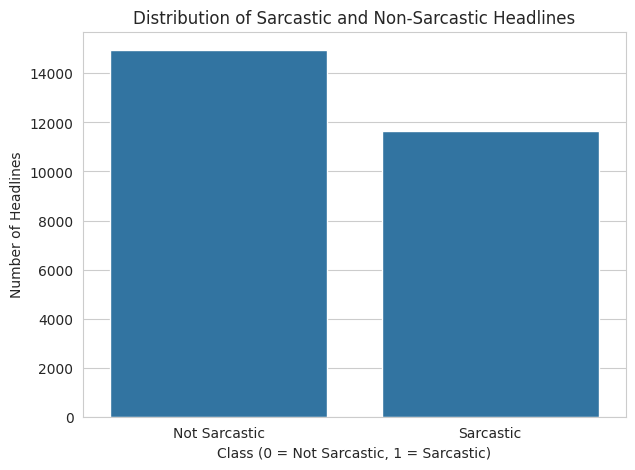

In [10]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="is_sarcastic")

plt.title("Distribution of Sarcastic and Non-Sarcastic Headlines")
plt.xlabel("Class (0 = Not Sarcastic, 1 = Sarcastic)")
plt.ylabel("Number of Headlines")
plt.xticks([0, 1], ["Not Sarcastic", "Sarcastic"])

plt.show()


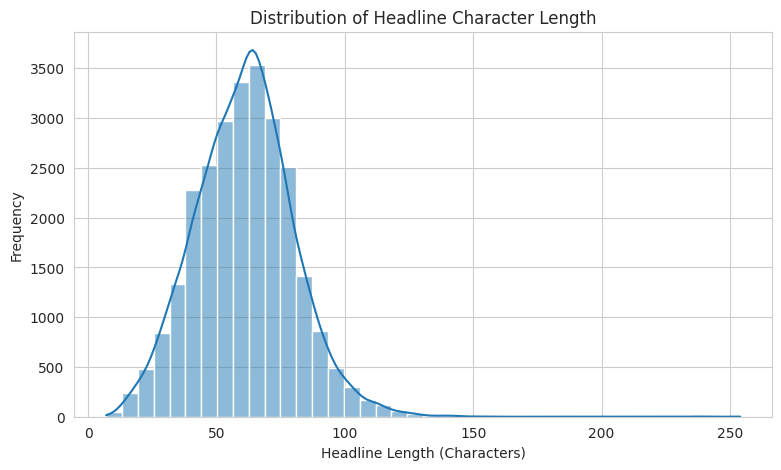

In [11]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="headline_length",
    bins=40,
    kde=True
)

plt.title("Distribution of Headline Character Length")
plt.xlabel("Headline Length (Characters)")
plt.ylabel("Frequency")

plt.show()


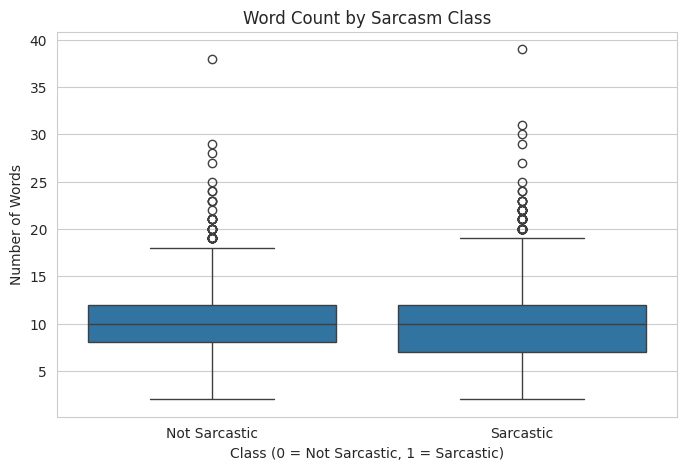

In [12]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="is_sarcastic",
    y="word_count"
)

plt.title("Word Count by Sarcasm Class")
plt.xlabel("Class (0 = Not Sarcastic, 1 = Sarcastic)")
plt.ylabel("Number of Words")
plt.xticks([0, 1], ["Not Sarcastic", "Sarcastic"])

plt.show()


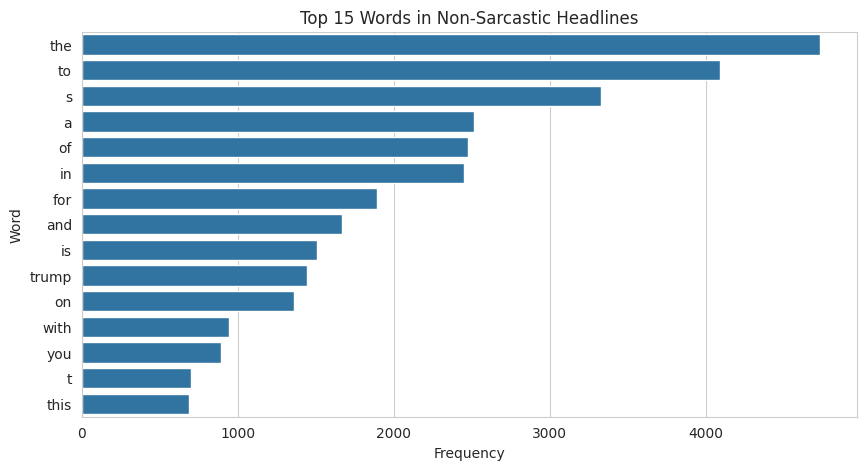

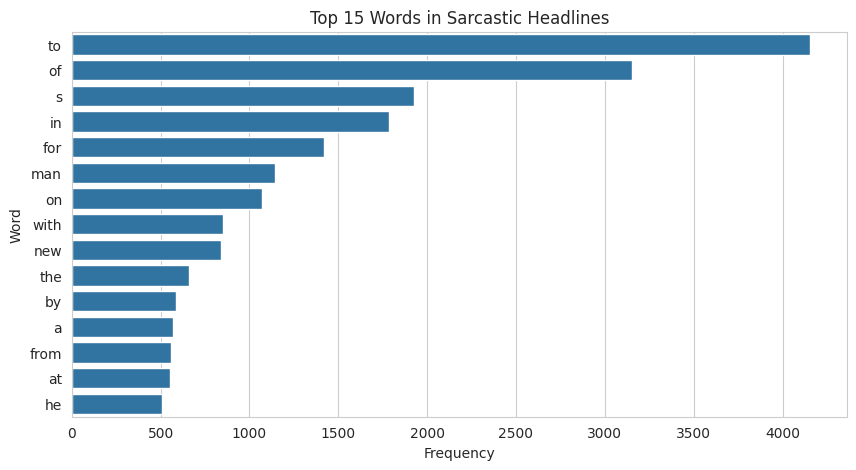

In [13]:

def get_top_words(texts, n=15):
    words = []

    for text in texts:
        # Convert to lowercase and extract words
        words.extend(re.findall(r"\b[a-zA-Z]+\b", text.lower()))

    return Counter(words).most_common(n)


# Most frequent words in non-sarcastic headlines
normal_words = get_top_words(
    df.loc[df["is_sarcastic"] == 0, "headline"]
)

# Most frequent words in sarcastic headlines
sarcastic_words = get_top_words(
    df.loc[df["is_sarcastic"] == 1, "headline"]
)


# Plot non-sarcastic words
words, counts = zip(*normal_words)

plt.figure(figsize=(10, 5))
sns.barplot(x=list(counts), y=list(words))

plt.title("Top 15 Words in Non-Sarcastic Headlines")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()


# Plot sarcastic words
words, counts = zip(*sarcastic_words)

plt.figure(figsize=(10, 5))
sns.barplot(x=list(counts), y=list(words))

plt.title("Top 15 Words in Sarcastic Headlines")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()


In [14]:

X = df["headline"]
y = df["is_sarcastic"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 21281
Testing samples: 5321


In [15]:

max_words = 5000
max_len = 50

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

# Fit tokenizer only on training data
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad or truncate every sequence to exactly 50 tokens
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

print("First padded sequence:")
print(X_train_pad[0])


Training shape: (21281, 50)
Testing shape: (5321, 50)
First padded sequence:
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0  149  572  573 1335  676   24 3267
 2097 1872    8  867  620   38  218  321]


In [16]:

model_rnn = Sequential([
    Input(shape=(50,)),
    Embedding(5000, 32),
    SimpleRNN(32),
    Dense(1, activation="sigmoid")
])

model_rnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_rnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,113 (633.25 KB)

 Trainable params: 162,113 (633.25 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:

history_rnn = model_rnn.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
599/599 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.7885 - loss: 0.4347 - val_accuracy: 0.8342 - val_loss: 0.3632
Epoch 2/5
599/599 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8988 - loss: 0.2516 - val_accuracy: 0.8445 - val_loss: 0.3743
Epoch 3/5
599/599 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9313 - loss: 0.1799 - val_accuracy: 0.8426 - val_loss: 0.4398
Epoch 4/5
599/599 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9719 - loss: 0.0832 - val_accuracy: 0.8098 - val_loss: 0.5545
Epoch 5/5
599/599 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9889 - loss: 0.0399 - val_accuracy: 0.8215 - val_loss: 0.6439


In [18]:

test_loss, test_accuracy = model_rnn.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


Test Loss: 0.6095564365386963
Test Accuracy: 82.48 %


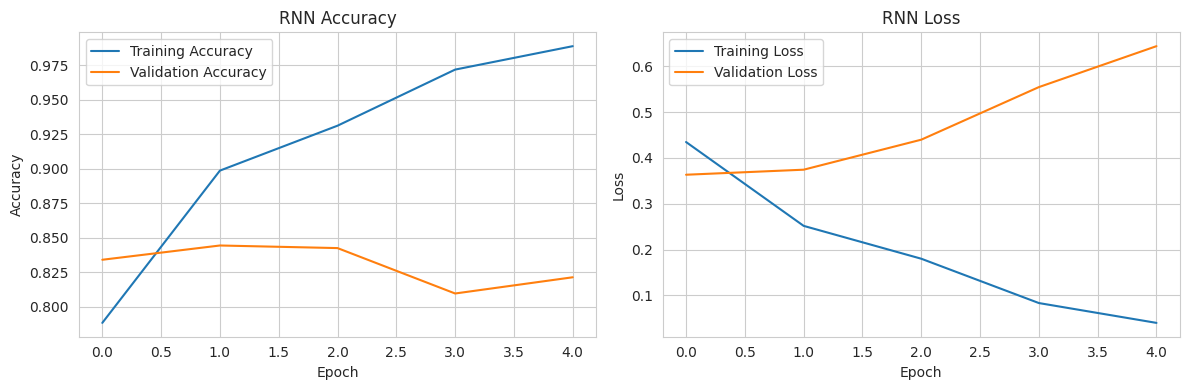

In [19]:

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_rnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_rnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("RNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_rnn.history["loss"], label="Training Loss")
plt.plot(history_rnn.history["val_loss"], label="Validation Loss")
plt.title("RNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()
